# PL7 — Context Engineering & RAG

### Generative AI · MSc in Artificial Intelligence · Lab 7

You will build, measure and improve a small RAG assistant for the fictional *Universidade de Vale Alto (UVA)*. The corpus is in **European Portuguese**, which makes model choice (multilingual embeddings, rerankers) part of the exercise.

**Learning goals**
1. Measure how a context window is spent and shrink it with *select* and *compress*.
2. Observe position effects ("lost in the middle") and write a structured, citation-friendly prompt.
3. Compare chunking strategies.
4. Build and evaluate dense, sparse (BM25), hybrid (RRF) and reranked retrieval with Recall@k and MRR.
5. Generate grounded answers with citations, metadata filtering and abstention, and evaluate them.

| Part | Topic | Time |
|---|---|---|
| 0 | Setup | 10 min |
| 1 | Context engineering | 25 min |
| 2 | Chunking | 10 min |
| 3 | Dense retrieval & metrics | 20 min |
| 4 | BM25 & hybrid search | 15 min |
| 5 | Reranking | 10 min |
| 6 | Grounded generation & evaluation | 20 min |
| 7 | Results & report | 10 min |
| ★ | Bonus: query rewriting, HyDE, agentic loop | at home |

**Deliverable:** this notebook, executed, with the results table in Part 7 and short answers to every ❓ question.

**Instructions.** Run the cells in order. Cells marked `# TODO` are yours to complete.

**Names / student numbers:** Tomás Henrique Alves Melo - PG60018

## Part 0 · Setup (10 min)

Use **Google Colab with a GPU runtime** (*Runtime → Change runtime type → T4 GPU*). Two LLM backends are supported:

* `"hf"`: a small open model running locally (free). Use `Qwen/Qwen2.5-1.5B-Instruct` on GPU, `Qwen/Qwen2.5-0.5B-Instruct` if you only have a CPU.
* `"anthropic"`: the Claude API, if you have a key. Faster and much stronger, which changes some results. Note which one you used in your report.

In [1]:
!pip -q install sentence-transformers rank_bm25 transformers accelerate anthropic

In [ ]:
import os, re, json, time, math, random, unicodedata
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

random.seed(0); np.random.seed(0)

EXECUTAR_BONUS = True   

In [ ]:
BACKEND = "hf"                            
import torch
HF_MODEL = ("Qwen/Qwen2.5-1.5B-Instruct" if torch.cuda.is_available()
            else "Qwen/Qwen2.5-0.5B-Instruct")      
ANTHROPIC_MODEL = "claude-haiku-5-5"        

if BACKEND == "hf":
    from transformers import pipeline
    _gen = pipeline("text-generation", model=HF_MODEL, dtype="auto", device_map="auto")
else:
    import anthropic, getpass
    if "ANTHROPIC_API_KEY" not in os.environ:
        os.environ["ANTHROPIC_API_KEY"] = getpass.getpass("Anthropic API key: ")
    _client = anthropic.Anthropic()

def llm(prompt, system="You are a helpful assistant.", max_tokens=300):
    """Single-turn call to the chosen backend. Deterministic (greedy) for reproducibility."""
    if BACKEND == "hf":
        msgs = [{"role": "system", "content": system}, {"role": "user", "content": prompt}]
        out = _gen(msgs, max_new_tokens=max_tokens, do_sample=False)
        return out[0]["generated_text"][-1]["content"].strip()
    r = _client.messages.create(model=ANTHROPIC_MODEL, max_tokens=max_tokens, system=system,
                                messages=[{"role": "user", "content": prompt}])
    return r.content[0].text.strip()

print("Backend:", BACKEND, "|", HF_MODEL if BACKEND == "hf" else ANTHROPIC_MODEL)
print(llm("Diz olá numa frase curta."))

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Backend: hf | Qwen/Qwen2.5-1.5B-Instruct
Olá, tudo bem? Como posso ajudar você hoje?


In [ ]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct") 

def n_tokens(text: str) -> int:
    return len(tok.encode(text))

def norm(text: str) -> str:
    """Lowercase and strip accents, for robust string matching."""
    text = unicodedata.normalize("NFKD", str(text).lower())
    return "".join(ch for ch in text if not unicodedata.combining(ch))

print(n_tokens("A propina anual é de 710 euros."), norm("Época Especial"))

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

13 epoca especial


### The corpus

`DOCS` holds 18 short UVA documents. Each has an `id`, `title`, `date` and `topic`. Two topics have **several versions** (`propinas`, `reembolso`), which you will need later. `LONG_REG` is a longer regulation you will chunk yourself in Part 2. `GOLD` is a hand-labelled evaluation set: question, ids of the relevant chunks, and a key string the answer must contain.

In [5]:
def D(id, title, date, text, topic=None):
    return {"id": id, "title": title, "date": date, "topic": topic or id, "text": text}

DOCS = [
    D("propinas-2024", "Propinas 2024/2025", "2024-07-01",
      "A propina anual para licenciaturas e mestrados integrados é de 697 euros, paga em 10 prestações mensais de outubro a julho. O não pagamento de três prestações consecutivas suspende a inscrição.", "propinas"),
    D("propinas-2026", "Propinas 2026/2027", "2026-07-01",
      "A propina anual para licenciaturas e mestrados integrados é de 710 euros. Pode ser paga numa prestação única, com 2% de desconto, ou em 10 prestações mensais. Um atraso superior a 60 dias implica a suspensão da inscrição.", "propinas"),
    D("reembolso-2023", "Política de reembolsos (versão 2023)", "2023-09-01",
      "Os estudantes que anulem a inscrição têm direito ao reembolso das prestações de propina já pagas se o pedido for feito até 14 dias após o início do semestre.", "reembolso"),
    D("reembolso-2026", "Política de reembolsos (versão 2026)", "2026-09-15",
      "O prazo para pedir o reembolso das prestações de propina após anulação da inscrição passa a ser de 30 dias após o início do semestre. O pedido é feito no portal académico, na secção Requerimentos, e o reembolso é processado em até 45 dias úteis.", "reembolso"),
    D("uc-4471", "Ficha da UC-4471 Aprendizagem Automática", "2026-07-15",
      "Unidade curricular UC-4471 Aprendizagem Automática: 6 ECTS, 2.º ano, 1.º semestre. Docente responsável: Prof.ª Helena Matos. Avaliação: projeto (50%) e exame (50%), com nota mínima de 8 valores em cada componente."),
    D("uc-4472", "Ficha da UC-4472 Processamento de Linguagem Natural", "2026-07-15",
      "Unidade curricular UC-4472 Processamento de Linguagem Natural: 6 ECTS, 3.º ano, 2.º semestre. Docente responsável: Prof. Rui Carvalho. Avaliação: dois trabalhos práticos (60%) e um teste escrito (40%). Pré-requisito recomendado: UC-4471."),
    D("clu-77", "Acesso ao cluster de GPUs (serviço CLU-77)", "2025-10-01",
      "Estudantes de mestrado e doutoramento podem pedir acesso ao cluster de GPUs através do formulário CLU-77 no portal de serviços informáticos. Cada projeto tem uma quota de 200 horas de GPU por semestre. Pedidos de estudantes de licenciatura exigem uma declaração do orientador."),
    D("ia-trabalhos", "Uso de IA generativa em trabalhos académicos", "2025-09-01",
      "É permitido usar ferramentas de IA generativa para apoio à escrita e à programação, desde que o uso seja declarado numa secção própria do trabalho. A submissão de texto gerado por IA como próprio, sem declaração, é considerada fraude académica (ver Regulamento Pedagógico, artigo 9.º)."),
    D("biblioteca", "Horários da Biblioteca Central", "2026-09-01",
      "A Biblioteca Central está aberta de segunda a sexta das 8h30 às 23h00 e aos sábados das 9h00 às 18h00. Em época de exames abre também ao domingo. O empréstimo domiciliário é de 15 dias, renovável duas vezes."),
    D("eduroam", "Rede sem fios eduroam", "2025-02-01",
      "A universidade disponibiliza a rede eduroam em todos os edifícios. Configuração: utilizador no formato numero@alunos.uva.pt e a palavra-passe do portal académico. Problemas devem ser reportados ao helpdesk pela extensão 5050."),
    D("erasmus", "Programa Erasmus+", "2026-01-05",
      "As candidaturas para mobilidade Erasmus+ no ano letivo seguinte decorrem de 1 a 31 de janeiro. Requisitos: ter concluído pelo menos 60 ECTS e média mínima de 12 valores. A bolsa mensal varia entre 300 e 500 euros consoante o país de destino."),
    D("trabalhador-estudante", "Estatuto de trabalhador-estudante", "2025-09-01",
      "O estatuto de trabalhador-estudante é pedido no início de cada semestre, com contrato de trabalho ou declaração da entidade empregadora. Dá direito a época especial de exames, dispensa de frequência mínima e escolha preferencial de horários."),
    D("cantina", "Cantina e refeições sociais", "2026-09-01",
      "A cantina serve almoço das 12h00 às 14h30 e jantar das 19h00 às 21h00. A refeição social custa 3,10 euros. Existe sempre uma opção vegetariana."),
    D("alojamento", "Residências universitárias", "2026-06-01",
      "As candidaturas a alojamento nas residências são feitas em julho para o ano letivo seguinte. Os bolseiros têm prioridade. O preço mensal de um quarto duplo é de 85 euros para bolseiros e 160 euros para não bolseiros."),
    D("bolsas", "Bolsas de estudo de ação social", "2026-05-20",
      "A candidatura à bolsa de estudo é feita online na plataforma da DGES entre junho e setembro. O valor da bolsa depende do rendimento per capita do agregado familiar e cobre pelo menos o valor da propina."),
    D("calendario-2026", "Calendário escolar 2026/2027", "2026-06-30",
      "O 1.º semestre de 2026/2027 começa a 14 de setembro de 2026 e termina a 22 de janeiro de 2027. A época normal de exames do 1.º semestre decorre de 4 a 22 de janeiro. O 2.º semestre começa a 15 de fevereiro de 2027."),
    D("apoio-psicologico", "Gabinete de apoio psicológico", "2025-09-01",
      "O gabinete de apoio psicológico oferece consultas gratuitas e confidenciais, marcadas por e-mail para gap@uva.pt. Em situações urgentes existe atendimento sem marcação às quartas-feiras das 14h00 às 17h00."),
    D("portal", "Portal académico", "2025-09-01",
      "No portal académico é possível consultar notas, fazer inscrições em exames, submeter requerimentos e descarregar declarações de matrícula. A inscrição em exames da época de recurso deve ser feita até 5 dias úteis antes da data do exame."),
]

ID2DOC = {d["id"]: d for d in DOCS}

LONG_REG = """Regulamento Pedagógico da Universidade de Vale Alto (versão de setembro de 2025)

Artigo 1.º – Objeto
O presente regulamento define as regras de avaliação aplicáveis aos cursos de 1.º e 2.º ciclo e aos mestrados integrados da Universidade de Vale Alto. Aplica-se a todas as unidades curriculares, salvo disposição em contrário na respetiva ficha.

Artigo 2.º – Escala de classificação
A classificação das unidades curriculares é expressa numa escala inteira de 0 a 20 valores. Considera-se aprovado o estudante que obtenha classificação final igual ou superior a 10 valores. As classificações intermédias são arredondadas às décimas.

Artigo 3.º – Avaliação contínua
A avaliação contínua inclui pelo menos dois elementos de avaliação distribuídos ao longo do semestre. Nas unidades curriculares com componente prática é exigida a presença em pelo menos 75% das aulas práticas, exceto para estudantes com estatuto especial.

Artigo 4.º – Épocas de exame
Existem três épocas de exame: época normal, época de recurso e época especial. O estudante reprovado ou que não compareça na época normal pode apresentar-se à época de recurso, mediante inscrição prévia no portal académico.

Artigo 5.º – Época especial
Têm acesso à época especial os trabalhadores-estudantes, os atletas de alta competição, os dirigentes associativos e os finalistas a quem faltem no máximo duas unidades curriculares, até ao limite de 12 ECTS, para concluir o curso.

Artigo 6.º – Melhoria de classificação
O estudante pode requerer melhoria de classificação uma única vez em cada unidade curricular, na época de recurso do ano letivo seguinte ao da aprovação. Prevalece a classificação mais elevada. A melhoria está sujeita ao pagamento de uma taxa fixada anualmente.

Artigo 7.º – Revisão de prova
O estudante pode requerer a revisão de uma prova escrita no prazo de 3 dias úteis após a publicação da classificação. O pedido está sujeito a uma taxa de 25 euros, reembolsada se a classificação for alterada a favor do estudante.

Artigo 8.º – Prova oral complementar
Quando a classificação de um exame escrito se situe entre 8 e 9,4 valores, o docente responsável pode convocar o estudante para uma prova oral complementar, que decide a aprovação.

Artigo 9.º – Fraude académica
Constituem fraude académica o plágio, a cópia, a utilização de meios não autorizados durante as provas e a apresentação como próprio de conteúdo gerado por ferramentas de inteligência artificial sem a devida declaração. A fraude implica a anulação da prova e a abertura de processo disciplinar. A reincidência pode conduzir à suspensão até dois semestres.

Artigo 10.º – Publicação de classificações
As classificações são publicadas no portal académico no prazo máximo de 15 dias úteis após a realização da prova.

Artigo 11.º – Casos omissos
Os casos omissos são decididos pelo Conselho Pedagógico, ouvido o docente responsável pela unidade curricular.
"""

def G(q, relevant, answer): return {"q": q, "relevant": relevant, "answer": answer}

GOLD = [
    G("Qual é o prazo para pedir o reembolso das propinas?", ["reembolso-2026"], "30 dias"),
    G("Quanto custa a propina anual em 2026/2027?", ["propinas-2026"], "710"),
    G("Quem é a docente responsável pela UC-4471?", ["uc-4471"], "helena matos"),
    G("Quantas horas de GPU tem cada projeto no CLU-77?", ["clu-77"], "200"),
    G("Posso usar o ChatGPT para me ajudar a escrever o relatório?", ["ia-trabalhos"], "declar"),
    G("O que acontece se eu entregar um trabalho feito por IA sem avisar?", ["ia-trabalhos", "regped-art-9"], "fraude"),
    G("Quantas vezes posso tentar subir a nota de uma cadeira?", ["regped-art-6"], "uma unica"),
    G("Qual é a nota mínima para passar a uma cadeira?", ["regped-art-2"], "10"),
    G("Quem tem direito a época especial de exames?", ["regped-art-5", "trabalhador-estudante"], "trabalhador"),
    G("Até quando posso pedir para rever o meu exame?", ["regped-art-7"], "3 dias"),
    G("A que horas fecha a biblioteca ao sábado?", ["biblioteca"], "18"),
    G("Como me ligo à internet sem fios no campus?", ["eduroam"], "eduroam"),
    G("Que média preciso para fazer Erasmus?", ["erasmus"], "12"),
    G("Quanto paga um bolseiro por um quarto na residência?", ["alojamento"], "85"),
    G("Quando começa o primeiro semestre de 2026/2027?", ["calendario-2026"], "14 de setembro"),
    G("Qual é o peso dos trabalhos práticos na avaliação de PLN?", ["uc-4472"], "60"),
    G("Qual é o número de telemóvel do reitor?", [], "nao sei"),   # unanswerable: must abstain
]
print(len(DOCS), "docs |", n_tokens(LONG_REG), "tokens in LONG_REG |", len(GOLD), "gold questions")

18 docs | 809 tokens in LONG_REG | 17 gold questions


## Part 1 · Context engineering (25 min)

### 1.1 Where do the tokens go? (8 min)

Below is the context a naive support agent sends on **every** turn: a system prompt, 32 tool definitions, the last 40 messages of conversation (20 exchanges), every document in the knowledge base and, finally, the user's question.

In [ ]:
SYSTEM = ("És o assistente académico da Universidade de Vale Alto. Responde de forma clara, educada e concisa, "
          "em português europeu. Segue as regras institucionais, não inventes informação e encaminha casos "
          "sensíveis para os serviços competentes. ") * 4

TOOL_NAMES = ["get_grades", "update_address", "book_room", "cancel_booking", "list_courses", "enrol_exam",
    "unenrol_exam", "get_timetable", "request_certificate", "pay_fee", "get_fees", "search_regulations",
    "open_ticket", "close_ticket", "get_menu", "reserve_meal", "library_search", "renew_loan", "get_calendar",
    "erasmus_status", "scholarship_status", "upload_document", "change_password", "get_wifi_config",
    "contact_tutor", "book_counselling", "list_events", "parking_permit", "lost_and_found", "print_quota",
    "gpu_quota", "send_email"]
TOOLS = [{"name": n, "description": f"Tool that lets the assistant {n.replace('_', ' ')} in the UVA systems for the current student.",
          "input_schema": {"type": "object", "properties": {"student_id": {"type": "string"}, "details": {"type": "string"}},
                           "required": ["student_id"]}} for n in TOOL_NAMES]
TOOLS_TXT = json.dumps(TOOLS, ensure_ascii=False, indent=1)

HISTORY = []   
for g in GOLD[4:16] * 2:
    HISTORY += [f"Utilizador: {g['q']}", "Assistente: Segundo os documentos da universidade, " + DOCS[len(HISTORY) % len(DOCS)]["text"]]
HISTORY = HISTORY[-40:]
HISTORY_TXT = "\n".join(HISTORY)

DOCS_TXT = "\n\n".join(f"[{d['id']}] {d['title']}\n{d['text']}" for d in DOCS)
QUERY = "Qual é o prazo para pedir o reembolso das propinas?"

COMPONENTS = {"system": SYSTEM, "tools": TOOLS_TXT, "history": HISTORY_TXT, "documents": DOCS_TXT, "query": QUERY}

,component,tokens,share_%
0,system,249,3.6
1,tools,3066,44.9
2,history,1912,28.0
3,documents,1588,23.2
4,query,17,0.2


TOTAL: 6832


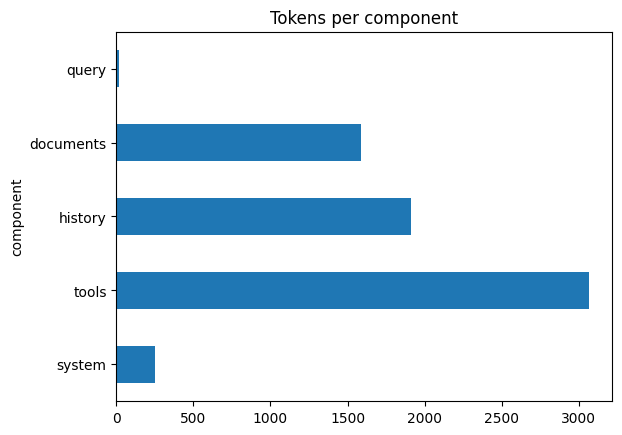

In [7]:
def budget_table(components: dict) -> pd.DataFrame:
    """Uma linha por componente, com o nº de tokens e a percentagem do total (1 casa decimal)."""
    df = pd.DataFrame({"component": list(components),
                       "tokens": [n_tokens(text) for text in components.values()]})
    df["share_%"] = (100 * df["tokens"] / df["tokens"].sum()).round(1)
    return df

df = budget_table(COMPONENTS)
display(df)
print("TOTAL:", df.tokens.sum())
df.set_index("component").tokens.plot.barh(title="Tokens per component"); plt.show()

❓ **Q1.** What share of the window is the user's actual question? Which component would you attack first, and with which strategy (*write, select, compress, isolate*)?

A pergunta do utilizador ocupa apenas 17 tokens em 6 832 (0,2 %) da janela. Os outros 99,8 % são o que se envia em todos os pedidos, quer a pergunta precise deles quer não. Por componente, na minha execução, obtive: ferramentas 3 066 tokens (44,9 %), histórico 1 912 (28,0 %), documentos 1 588 (23,2 %) e instruções de sistema 249 (3,6 %).

Atacaria primeiro as ferramentas, o maior componente, com **select**: são 32 definições enviadas sempre, quando uma pergunta sobre propinas só precisa de duas ou três (propinas, regulamento, abertura de pedido). Além de poupar tokens, reduz a *confusão* (ferramentas a mais levam a escolhas erradas). Segue-se **compress** no histórico (manter só as últimas mensagens ou um resumo), **select** nos documentos (só os excertos relevantes, que é precisamente o papel do RAG) e **compress** nas instruções de sistema, onde a mesma frase está repetida 4 vezes. As outras duas estratégias entram em tarefas mais longas: **write** (guardar notas e memória fora da janela e trazê-las só quando são precisas) e **isolate** (um subagente com janela própria que devolve só o resultado).

Now apply **select** and **compress** to bring the total **under 1,500 tokens** while keeping what the query needs. Suggested moves: keep only tools relevant to the query, keep the last 4 history lines, keep only the 3 documents with the largest word overlap with the query. Do not remove the query.

In [ ]:
def overlap(a: str, b: str) -> int:
    wa = set(re.findall(r"\w+", norm(a))); wb = set(re.findall(r"\w+", norm(b)))
    return len(wa & wb)

RELEVANT_TOOL_NAMES = {"get_fees", "search_regulations", "open_ticket"}

def shrink(components: dict, query: str) -> dict:
    """select + compress: devolve um novo dict com as mesmas chaves, abaixo de 1 500 tokens."""
    sentences = [s for s in re.split(r"(?<=\.)\s+", components["system"].strip()) if s]
    system = " ".join(dict.fromkeys(sentences))
    tools = [t for t in json.loads(components["tools"]) if t["name"] in RELEVANT_TOOL_NAMES]
    history = "\n".join(components["history"].split("\n")[-4:])
    ranked = sorted(DOCS, key=lambda d: overlap(query, d["title"] + " " + d["text"]), reverse=True)
    documents = "\n\n".join(f"[{d['id']}] {d['title']}\n{d['text']}" for d in ranked[:3])
    return {"system": system,
            "tools": json.dumps(tools, ensure_ascii=False, indent=1),
            "history": history,
            "documents": documents,
            "query": query}

small = shrink(COMPONENTS, QUERY)
df2 = budget_table(small); display(df2); print("TOTAL:", df2.tokens.sum())
assert set(small) == set(COMPONENTS) and small["query"] == QUERY and df2.tokens.sum() < 1500
print(f"Redução: {df.tokens.sum()} -> {df2.tokens.sum()} tokens ({1 - df2.tokens.sum() / df.tokens.sum():.0%} a menos)")
print("Docs kept:", re.findall(r"^\[(.+?)\]", small["documents"], flags=re.M))

,component,tokens,share_%
0,system,62,7.2
1,tools,289,33.7
2,history,218,25.4
3,documents,271,31.6
4,query,17,2.0


TOTAL: 857
Redução: 6832 -> 857 tokens (87% a menos)
Docs kept: ['reembolso-2026', 'propinas-2024', 'apoio-psicologico']


❓ **Q2.** Which three documents did the word-overlap rule keep? Is `reembolso-2026` among them? Is there an **outdated version** of a document, or a document that has nothing to do with the question? Print `overlap()` for each kept document: which words caused the match? Which failure modes from the lecture does this illustrate, and what would make the selection better?

In [9]:
kept = re.findall(r"^\[(.+?)\]", small["documents"], flags=re.M)
q_words = set(re.findall(r"\w+", norm(QUERY)))
print("Documentos mantidos, sobreposição e palavras em comum com a pergunta:")
for doc_id in kept:
    d = ID2DOC[doc_id]; txt = d["title"] + " " + d["text"]
    print(f"  {doc_id:18s} overlap={overlap(QUERY, txt)}  ->", sorted(q_words & set(re.findall(r"\w+", norm(txt)))))
print("\nreembolso-2026 está entre os 3?", "reembolso-2026" in kept)
print("Versões desatualizadas entre os 3:", [i for i in kept if i in ("propinas-2024", "reembolso-2023")])
print("\nTop-6 por sobreposição:", [(d["id"], overlap(QUERY, d["title"] + " " + d["text"]))
                                    for d in sorted(DOCS, key=lambda d: -overlap(QUERY, d["title"] + " " + d["text"]))[:6]])

Documentos mantidos, sobreposição e palavras em comum com a pergunta:
  reembolso-2026     overlap=7  -> ['das', 'e', 'o', 'para', 'pedir', 'prazo', 'reembolso']
  propinas-2024      overlap=4  -> ['e', 'o', 'para', 'propinas']
  apoio-psicologico  overlap=4  -> ['das', 'e', 'o', 'para']

reembolso-2026 está entre os 3? True
Versões desatualizadas entre os 3: ['propinas-2024']

Top-6 por sobreposição: [('reembolso-2026', 7), ('propinas-2024', 4), ('apoio-psicologico', 4), ('propinas-2026', 3), ('reembolso-2023', 3), ('ia-trabalhos', 3)]


A regra manteve `reembolso-2026` (sobreposição 7), `propinas-2024` (4) e `apoio-psicologico` (4). Sim, `reembolso-2026` está lá, mas é quase sorte, porque a seleção conta palavras e não avalia significado. Os outros dois são maus: `propinas-2024` é uma versão desatualizada (697 €, substituída por `propinas-2026`) e `apoio-psicologico` não tem nada a ver com a pergunta.

As palavras que causaram o match explicam porquê. `reembolso-2026` partilha *pedir, prazo, reembolso* (palavras de conteúdo) mas também *das, e, o, para*. `apoio-psicologico` partilha **apenas** *das, e, o, para*, isto é, palavras funcionais sem valor informativo, e `propinas-2024` partilha *propinas* mais *e, o, para*. Sem remover stop words, sem IDF (que dá mais peso a palavras raras) e sem *stemming* ("propinas" ≠ "propina"), "o" conta tanto como "reembolso".

Modos de falha ilustrados: *distração* (`apoio-psicologico` ocupa espaço e atenção sem ajudar) e *choque/clash* (`propinas-2024` e `propinas-2026` dão valores diferentes para a mesma coisa; o mesmo podia acontecer com `reembolso-2023` e `reembolso-2026`, 14 vs 30 dias, se a pergunta ou o top-k fossem ligeiramente diferentes).

Como melhorar a seleção: remover stop words e usar IDF (ou seja, BM25) ou embeddings em vez de contagem simples; acrescentar um reranker; aplicar um filtro de metadados que fique só com a versão mais recente de cada tópico (`latest_only`, Parte 6.1); e usar um limiar de relevância em vez de um top-3 fixo.

### 1.2 Lost in the middle (9 min)

We hide one relevant document (the "needle") among the other 17 and move it from the start to the end of the context. For each position we ask 5 questions and count correct answers.

In [10]:
NEEDLE_TESTS = [  # (question, needle doc id, key string in a correct answer)
    ("Quem é a docente responsável pela UC-4471?", "uc-4471", "helena matos"),
    ("Quantas horas de GPU tem cada projeto no CLU-77?", "clu-77", "200"),
    ("A que horas fecha a biblioteca ao sábado?", "biblioteca", "18"),
    ("Que média preciso para fazer Erasmus?", "erasmus", "12"),
    ("Quanto paga um bolseiro por um quarto na residência?", "alojamento", "85"),
]

def format_docs(docs):
    return "\n\n".join(f"[{d['id']}] {d['title']}\n{d['text']}" for d in docs)

In [11]:
def build_context(needle_id: str, position: float) -> list:
    """Todos os DOCS, com a agulha na posição relativa `position` (0.0 = primeiro, 1.0 = último)."""
    others = [d for d in DOCS if d["id"] != needle_id]
    random.Random(42).shuffle(others)          # mesma ordem dos distratores em todas as posições
    others.insert(round(position * len(others)), ID2DOC[needle_id])
    return others

assert build_context("uc-4471", 0.0)[0]["id"] == "uc-4471"
assert build_context("uc-4471", 1.0)[-1]["id"] == "uc-4471"
assert len(build_context("uc-4471", 0.5)) == len(DOCS)

position 0.00: 5/5


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


position 0.25: 5/5
position 0.50: 5/5
position 0.75: 5/5
position 1.00: 5/5


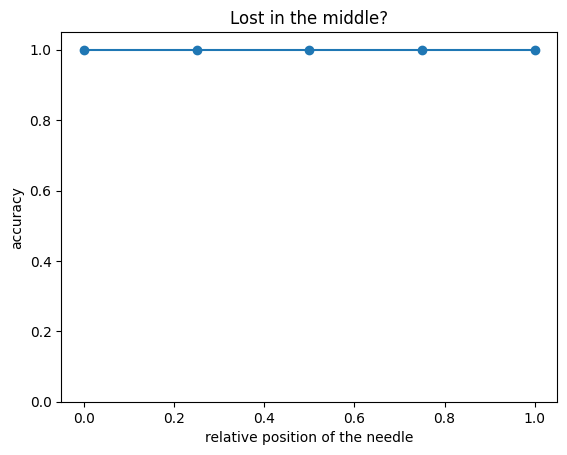

In [12]:
POSITIONS = [0.0, 0.25, 0.5, 0.75, 1.0]
acc = []
for p in POSITIONS:
    ok = 0
    for q, needle, key in NEEDLE_TESTS:
        ctx = format_docs(build_context(needle, p))
        ans = llm(f"Documentos:\n{ctx}\n\nPergunta: {q}\nResponde numa frase curta.", max_tokens=60)
        ok += key in norm(ans)
    acc.append(ok / len(NEEDLE_TESTS))
    print(f"position {p:.2f}: {ok}/{len(NEEDLE_TESTS)}")

plt.plot(POSITIONS, acc, marker="o"); plt.ylim(0, 1.05)
plt.xlabel("relative position of the needle"); plt.ylabel("accuracy"); plt.title("Lost in the middle?"); plt.show()

❓ **Q3.** Do you see a U-shape? Our context is only ~1.6k tokens and we use 5 questions, so results are noisy. What would you change to make the experiment more convincing (context length, number of questions, model size)?

Não. Na minha execução (Qwen2.5-1.5B-Instruct) a exatidão foi **5/5 (100 %) nas cinco posições**: a curva é plana, sem U e sem sequer um pequeno afundamento a meio. Isto não prova que o *lost in the middle* não existe, só que esta experiência não tem poder para o detetar. O contexto tem ~1,6 mil tokens (curto para o modelo), cada pergunta tem palavras muito distintivas (`UC-4471`, `CLU-77`, biblioteca, Erasmus, residência) que localizam o documento sem esforço, e com 5 perguntas cada erro vale 20 pontos percentuais. Como diz a lição (Liu et al., 2024), em contextos curtos e com modelos capazes o efeito pode quase desaparecer.

O que mudaria para a experiência ser convincente: (1) **contexto muito mais longo** (dezenas de milhares de tokens, juntando muitos documentos distratores), que é onde o efeito aparece; (2) **muito mais perguntas** (dezenas) e **várias ordenações de distratores** (várias sementes), reportando a média e o intervalo de confiança; (3) **distratores mais parecidos com a agulha** (por exemplo, outras fichas de UC), para a pergunta ser mais difícil; (4) **comparar modelos de tamanhos diferentes** (0.5B, 1.5B, um modelo maior), porque o efeito depende do modelo.

### 1.3 A structured, citation-friendly prompt (8 min)

Write `build_prompt(question, docs)` following the lecture: documents first, wrapped in tags **with id, title and date**; question last. `SYSTEM_RAG` asks for citations, abstention and the most recent version.

In [13]:
SYSTEM_RAG = ("És o assistente académico da Universidade de Vale Alto. Responde em português europeu, numa ou duas frases, "
              "usando APENAS os documentos fornecidos. Cita o id de cada documento usado entre parênteses retos, por exemplo "
              "[id-do-documento]. Se existirem versões diferentes do mesmo documento, usa a mais recente (data mais tardia). "
              "Se a resposta não estiver nos documentos, responde exatamente: 'Não sei com base nos documentos disponíveis.'")

def build_prompt(question: str, docs: list) -> str:
    """Documentos primeiro (com id, título e data: para citar e para escolher a versão mais recente); pergunta no fim."""
    lines = ["<documents>"]
    for d in docs:
        lines += [f'<doc id="{d["id"]}" title="{d["title"]}" date="{d["date"]}">', d["text"], "</doc>"]
    lines += ["</documents>", "", "<question>", question, "</question>"]
    return "\n".join(lines)

def naive_prompt(question: str, docs: list) -> str:
    return "Contexto: " + " ".join(d["text"] for d in docs) + f"\nPergunta: {question}"

_demo = build_prompt("P?", [ID2DOC["cantina"]])
assert _demo.startswith('<documents>\n<doc id="cantina"') and _demo.endswith("<question>\nP?\n</question>")

clash_docs = [ID2DOC["reembolso-2023"], ID2DOC["cantina"], ID2DOC["reembolso-2026"]]   # outdated version first
q = "Qual é o prazo para pedir o reembolso das propinas?"
naive_a = llm(naive_prompt(q, clash_docs))
structured_a = llm(build_prompt(q, clash_docs), system=SYSTEM_RAG)
abstain_a = llm(build_prompt("Qual é o número de telemóvel do reitor?", clash_docs), system=SYSTEM_RAG)
print("NAIVE     :", naive_a)
print("STRUCTURED:", structured_a)
print("ABSTAIN?  :", abstain_a)

NAIVE     : O prazo para pedir o reembolso das prestações de propina após anulação da inscrição é de 14 dias após o início do semestre.
STRUCTURED: De acordo com a política de reembolsos atualizada (versão 2026), o prazo para pedir o reembolso das prestações de propina após anulação da inscrição passou a ser de 30 dias após o início do semestre.
ABSTAIN?  : Não sei com base nos documentos disponíveis.


❓ **Q4.** Compare the naive and the structured answers: which deadline does each give (14 or 30 days)? Did the structured prompt resolve the *clash* between the 2023 and 2026 policies? Did it cite in the requested `[id]` format? Did the model abstain on the unanswerable question? If it still fails, is that a prompt problem or something you should fix **before** the prompt (hint: Part 6)?

In [14]:
def prazo(a: str) -> str:
    a = norm(a)
    return "30 dias" if "30 dias" in a else "14 dias" if "14 dias" in a else "nenhum dos dois"

print("Prazo no prompt ingénuo     :", prazo(naive_a))
print("Prazo no prompt estruturado :", prazo(structured_a))
print("Citações no formato [id] (estruturado):", re.findall(r"\[[a-z0-9]+(?:-[a-z0-9]+)*\]", structured_a) or "nenhuma")
print("Absteve-se na pergunta sem resposta?    :", "nao sei" in norm(abstain_a))

Prazo no prompt ingénuo     : 14 dias
Prazo no prompt estruturado : 30 dias
Citações no formato [id] (estruturado): nenhuma
Absteve-se na pergunta sem resposta?    : True


O prompt **ingénuo** respondeu **14 dias** (o prazo da política de 2023, que vem primeiro no contexto e vem sem data); o **estruturado** respondeu **30 dias**, o prazo em vigor (versão 2026). Portanto, aqui, as tags com `id/title/date` mais a instrução "usa a versão mais recente" **resolveram o choque** entre as duas políticas. Mas o estruturado **não citou no formato pedido**: escreveu "(versão 2026)" por extenso em vez de `[reembolso-2026]`, uma falha de seguimento de instruções do modelo pequeno. Na pergunta sem resposta (telemóvel do reitor) **absteve-se** corretamente, com a frase prescrita.

**Prompt ou algo a resolver antes do prompt?** Os dois. O choque entre versões deve ser resolvido antes do prompt: pedir ao modelo para escolher pela data funcionou com 3 documentos, mas é frágil (com mais versões e mais ruído pode falhar), enquanto um filtro de metadados (`latest_only`, Parte 6.1) é determinístico e mais barato. Já a falha no formato das citações é um problema de **prompt/modelo**; trato-o na Parte 6.2b (exemplo no prompt) e continuo a verificar as citações em código, porque não se pode confiar que o modelo as escreve bem.

## Part 2 · Chunking (10 min)

Implement two strategies for `LONG_REG` and compare them on structure (how many chunks mix articles or start mid-article) and on what they offer for retrieval and citations:

* `fixed_chunks`: windows of `size` words with `overlap` words of overlap.
* `article_chunks`: one chunk per *Artigo*, with a descriptive title (structure-aware chunking with a contextual header). Use the id format **`regped-art-{n}`**, which the gold set relies on.

In [ ]:
def fixed_chunks(text: str, size: int = 60, overlap: int = 15) -> list:
    """Janelas de `size` palavras; cada janela começa `size - overlap` palavras depois da anterior."""
    if size <= 0 or not 0 <= overlap < size:
        raise ValueError("É necessário 0 <= overlap < size.")
    words = text.split()
    step = size - overlap
    chunks = []
    for start in range(0, len(words), step):
        end = min(start + size, len(words))
        chunks.append(" ".join(words[start:end]))
        if end == len(words):         
            break
    return chunks

def article_chunks(text: str, doc_title="Regulamento Pedagógico", date="2025-09-01") -> list:
    """Um chunk por artigo, com título descritivo (cabeçalho contextual) e id estável regped-art-{n}."""
    chunks = []
    for piece in re.split(r"(?=Artigo \d+\.º)", text):      
        piece = piece.strip()
        m = re.match(r"Artigo (\d+)\.º\s*[–-]\s*(.+)", piece)
        if not m:                                          
            continue
        number, heading = m.group(1), m.group(2).strip()
        art_id = f"regped-art-{number}"
        chunks.append({"id": art_id, "title": f"{doc_title}, Artigo {number}.º {heading}",
                       "date": date, "topic": art_id, "text": piece})
    return chunks

# testes rápidos
_f = fixed_chunks("a b c d e f g h i j", size=4, overlap=1)
assert _f == ["a b c d", "d e f g", "g h i j"], _f
assert fixed_chunks("a b c", size=10, overlap=2) == ["a b c"]

In [16]:
fixed = fixed_chunks(LONG_REG)
arts = article_chunks(LONG_REG)
mixed = sum(len(re.findall(r"Artigo \d+\.º", c)) >= 2 for c in fixed)
midstart = sum(not c.startswith("Artigo") for c in fixed[1:])   # the first chunk starts with the document title
print(f"fixed  : {len(fixed)} chunks | {mixed} mix two articles | {midstart} of {len(fixed)-1} start mid-article")
art_mixed = sum(len(re.findall(r"Artigo \d+\.º", c["text"])) >= 2 for c in arts)
art_mid = sum(not c["text"].startswith("Artigo") for c in arts)
print(f"article: {len(arts)} chunks | {art_mixed} mix two articles | {art_mid} start mid-article ->", [c["id"] for c in arts][:4], "...")
print("\nExample fixed chunk:\n", fixed[5][:300])
print("\nExample article chunk title:", arts[5]["title"])

CHUNKS = DOCS + arts
ID2CHUNK = {c["id"]: c for c in CHUNKS}
assert "regped-art-6" in ID2CHUNK, "article ids must look like regped-art-6"
print("\nIndex size:", len(CHUNKS), "chunks")

fixed  : 10 chunks | 7 mix two articles | 7 of 9 start mid-article
article: 11 chunks | 0 mix two articles | 0 start mid-article -> ['regped-art-1', 'regped-art-2', 'regped-art-3', 'regped-art-4'] ...

Example fixed chunk:
 de classificação O estudante pode requerer melhoria de classificação uma única vez em cada unidade curricular, na época de recurso do ano letivo seguinte ao da aprovação. Prevalece a classificação mais elevada. A melhoria está sujeita ao pagamento de uma taxa fixada anualmente. Artigo 7.º – Revisão 

Example article chunk title: Regulamento Pedagógico, Artigo 6.º Melhoria de classificação

Index size: 29 chunks


❓ **Q5.** Look at the example fixed-size chunk: it starts in the middle of an article heading (so the article number is lost) and runs into the next article. If it were retrieved alone, could the model tell which rule each sentence belongs to? How does the `title` field of `article_chunks` help, both for retrieval and for citations?

Não, não de forma fiável. O chunk de exemplo começa em "de classificação O estudante pode requerer melhoria…" (o cabeçalho "Artigo 6.º – Melhoria" foi cortado e perdeu-se o número do artigo) e termina já no cabeçalho do Artigo 7.º. Se for recuperado sozinho, o modelo não sabe a que artigo pertence cada frase: pode atribuir a regra da melhoria de nota à revisão de prova (ou ao contrário) e não consegue citar o artigo certo. Nos números da minha execução, **7 dos 10** chunks de tamanho fixo misturam dois artigos e **7 dos 9** (excluindo o primeiro) começam a meio de um artigo; nos chunks por artigo são 0 e 0.

O campo `title` ("Regulamento Pedagógico, Artigo 6.º Melhoria de classificação") ajuda de duas formas. **Na recuperação**, porque faz parte do texto indexado (`passage_text` = título + texto): palavras como "melhoria" e "classificação" entram no embedding e no BM25 e dão contexto ao excerto (é o *cabeçalho contextual* da lição). **Nas citações**, porque cada chunk tem um `id` estável (`regped-art-6`) e um título legível que o modelo pode citar e que se verifica em código. Em contrapartida, os chunks por artigo têm tamanhos desiguais e só funcionam porque o regulamento é bem estruturado; num texto sem estrutura, o tamanho fixo com sobreposição é a alternativa.

## Part 3 · Dense retrieval & metrics (20 min)

We use `intfloat/multilingual-e5-small`, a small multilingual bi-encoder. **E5 models expect prefixes:** `"query: "` for questions and `"passage: "` for documents.

In [17]:
from sentence_transformers import SentenceTransformer
emb_model = SentenceTransformer("intfloat/multilingual-e5-small")

def passage_text(c: dict) -> str:
    return f"{c['title']}. {c['text']}"

P_EMB = emb_model.encode(["passage: " + passage_text(c) for c in CHUNKS], normalize_embeddings=True)
print(P_EMB.shape)

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

... (5 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

(29, 384)


In [18]:
def dense_search(query: str, k: int = 10) -> list:
    """Ids dos k melhores CHUNKS por semelhança de cosseno (vetores normalizados -> produto interno)."""
    q_emb = emb_model.encode("query: " + query, normalize_embeddings=True)
    scores = P_EMB @ q_emb
    best = np.argsort(-scores, kind="stable")[:k]
    return [CHUNKS[i]["id"] for i in best]

print(dense_search("Quantas vezes posso tentar subir a nota de uma cadeira?", k=5))

['portal', 'regped-art-4', 'reembolso-2023', 'regped-art-7', 'regped-art-5']


Now the metrics. For a ranked list of ids and the set of relevant ids:

* **Recall@k** = |relevant ∩ top-k| / |relevant|
* **Reciprocal rank** = 1 / (rank of the first relevant id), or 0 if none is found. **MRR** is its mean over questions.

In [19]:
def recall_at_k(ranked: list, relevant: list, k: int) -> float:
    """Fração dos ids relevantes que aparecem nas k primeiras posições de `ranked`."""
    if not relevant:
        return 0.0
    return len(set(ranked[:k]) & set(relevant)) / len(set(relevant))

def reciprocal_rank(ranked: list, relevant: list) -> float:
    """1 / posição do primeiro id relevante (posições a contar de 1); 0.0 se nenhum aparecer."""
    for pos, doc_id in enumerate(ranked, start=1):
        if doc_id in set(relevant):
            return 1.0 / pos
    return 0.0

assert recall_at_k(["a", "b", "c"], ["c", "z"], 2) == 0.0
assert recall_at_k(["a", "b", "c"], ["c", "z"], 3) == 0.5
assert reciprocal_rank(["a", "b", "c"], ["b"]) == 0.5
assert reciprocal_rank(["a", "b", "c"], ["z"]) == 0.0

In [20]:
RESULTS, MISSES = {}, {}

def evaluate(search_fn, name: str, depth: int = 10) -> dict:
    rows, t0 = [], time.time()
    for g in GOLD:
        if not g["relevant"]:
            continue                                    # unanswerable questions are not retrieval tests
        ranked = search_fn(g["q"], k=depth)
        rows.append({"q": g["q"], "R@1": recall_at_k(ranked, g["relevant"], 1),
                     "R@5": recall_at_k(ranked, g["relevant"], 5), "RR": reciprocal_rank(ranked, g["relevant"])})
    df = pd.DataFrame(rows)
    res = {"Recall@1": df["R@1"].mean(), "Recall@5": df["R@5"].mean(), "MRR": df["RR"].mean(),
           "ms/query": 1000 * (time.time() - t0) / len(df)}
    RESULTS[name] = {k: round(float(v), 3) for k, v in res.items()}
    MISSES[name] = df[df["R@5"] < 1]["q"].tolist()
    return RESULTS[name]

print(evaluate(dense_search, "dense"))
print("Not fully found in top-5:", MISSES["dense"])

{'Recall@1': 0.719, 'Recall@5': 0.875, 'MRR': 0.833, 'ms/query': 13.627}
Not fully found in top-5: ['Quantas vezes posso tentar subir a nota de uma cadeira?', 'Qual é a nota mínima para passar a uma cadeira?']


In [21]:
def first_rank(ranked: list, relevant: list):
    """Posição (a contar de 1) do primeiro id relevante, ou NaN se não aparecer."""
    for pos, doc_id in enumerate(ranked, start=1):
        if doc_id in relevant:
            return pos
    return np.nan

def rank_table(methods: dict, depth: int = 10) -> pd.DataFrame:
    """Para cada pergunta com resposta e cada método: posição do 1.º excerto relevante (NaN = fora do top-depth)."""
    rows = []
    for g in GOLD:
        if not g["relevant"]:
            continue
        row = {"question": g["q"][:62]}
        for name, fn in methods.items():
            row[name] = first_rank(fn(g["q"], k=depth), g["relevant"])
        rows.append(row)
    return pd.DataFrame(rows)

def show_ranks(rt: pd.DataFrame):
    out = rt.copy()
    for c in out.columns[1:]:
        out[c] = out[c].map(lambda x: "-" if pd.isna(x) else int(x))
    display(out)

def quick_eval(search_fn, depth: int = 10) -> dict:
    """Como evaluate(), mas sem guardar em RESULTS (para variações rápidas)."""
    r1, r5, rr = [], [], []
    for g in GOLD:
        if not g["relevant"]:
            continue
        ranked = search_fn(g["q"], k=depth)
        r1.append(recall_at_k(ranked, g["relevant"], 1)); r5.append(recall_at_k(ranked, g["relevant"], 5))
        rr.append(reciprocal_rank(ranked, g["relevant"]))
    return {"Recall@1": round(float(np.mean(r1)), 3), "Recall@5": round(float(np.mean(r5)), 3), "MRR": round(float(np.mean(rr)), 3)}

❓ **Q6.** Which questions does dense retrieval miss? Look at their wording: exact codes (`UC-4471`, `CLU-77`), abbreviations (`PLN`), or paraphrases and colloquial words (*cadeira*, *subir a nota*)?

In [22]:
print("Perguntas sem todos os relevantes no top-5 (denso):")
for q in MISSES["dense"]:
    g = next(g for g in GOLD if g["q"] == q)
    print(f"- {q}\n    relevante(s): {g['relevant']} | top-5 do denso: {dense_search(q, 5)}")
print("\nPerguntas com códigos/siglas e o respetivo Recall@5 no denso:")
for g in GOLD:
    if re.search(r"UC-\d+|CLU-\d+|PLN", g["q"]):
        print(f"- {g['q']} -> {recall_at_k(dense_search(g['q'], 5), g['relevant'], 5):.2f}")

Perguntas sem todos os relevantes no top-5 (denso):
- Quantas vezes posso tentar subir a nota de uma cadeira?
    relevante(s): ['regped-art-6'] | top-5 do denso: ['portal', 'regped-art-4', 'reembolso-2023', 'regped-art-7', 'regped-art-5']
- Qual é a nota mínima para passar a uma cadeira?
    relevante(s): ['regped-art-2'] | top-5 do denso: ['portal', 'alojamento', 'regped-art-5', 'erasmus', 'regped-art-8']

Perguntas com códigos/siglas e o respetivo Recall@5 no denso:
- Quem é a docente responsável pela UC-4471? -> 1.00
- Quantas horas de GPU tem cada projeto no CLU-77? -> 1.00
- Qual é o peso dos trabalhos práticos na avaliação de PLN? -> 1.00


O denso falha (relevante fora do top-5) em **duas perguntas**: *"Quantas vezes posso tentar subir a nota de uma cadeira?"* (relevante: `regped-art-6`) e *"Qual é a nota mínima para passar a uma cadeira?"* (relevante: `regped-art-2`). Têm a mesma causa: **linguagem coloquial e paráfrase**. "Cadeira" é *unidade curricular*, "nota" é *classificação* e "subir a nota" é *melhoria de classificação*, e o texto desses artigos quase não partilha vocabulário com a pergunta. O modelo pequeno encontra excertos vizinhos sobre avaliação (para a primeira, `portal`, `regped-art-4`, `regped-art-7`, `regped-art-5`) mas não o Artigo 6.º.

Não foram os códigos nem as siglas que falharam: as perguntas com `UC-4471`, `CLU-77` e `PLN` têm o relevante no top-5 (Recall@5 = 1). A fraqueza típica do denso com códigos não apareceu, provavelmente porque o corpus é minúsculo (29 excertos) e o código está no título do documento.

> **Read the metrics with care.** The evaluation has 16 answerable questions, so one question is worth 1/16 = 0.0625 of Recall@5. Differences of that size are one question, not a trend.

❓ **Q7 (2 min experiment).** Re-encode *without* the `query: ` / `passage: ` prefixes and re-evaluate as `"dense_noprefix"`. What happens? Is the difference larger than one question? Why does it matter to read the model card, even when a small test does not show the effect?

In [23]:
# 1. chunks codificados SEM o prefixo "passage: " (texto = passage_text(c), normalizado)
P_EMB_NP = emb_model.encode([passage_text(c) for c in CHUNKS], normalize_embeddings=True)

# 2. pesquisa SEM o prefixo "query: "
def dense_noprefix(query: str, k: int = 10) -> list:
    q_emb = emb_model.encode(query, normalize_embeddings=True)
    best = np.argsort(-(P_EMB_NP @ q_emb), kind="stable")[:k]
    return [CHUNKS[i]["id"] for i in best]

# 3. avaliação e comparação com a linha "dense"
print(evaluate(dense_noprefix, "dense_noprefix"))
print("Not fully found in top-5 (sem prefixos):", MISSES["dense_noprefix"])
display(pd.DataFrame(RESULTS).T.loc[["dense", "dense_noprefix"]])

{'Recall@1': 0.719, 'Recall@5': 0.938, 'MRR': 0.834, 'ms/query': 10.607}
Not fully found in top-5 (sem prefixos): ['Qual é a nota mínima para passar a uma cadeira?']


,Recall@1,Recall@5,MRR,ms/query
dense,0.719,0.875,0.833,13.627
dense_noprefix,0.719,0.938,0.834,10.607


Sem prefixos o resultado ficou praticamente igual: Recall@1 idêntico (0,719), MRR 0,834 contra 0,833 e Recall@5 0,938 contra 0,875, isto é, mais uma pergunta encontrada sem prefixos (1/16 = 0,0625). Uma diferença de uma só pergunta não é maior do que o ruído deste conjunto de 16 perguntas, por isso não permite concluir nada (nem sequer que "sem prefixos é melhor"); com apenas 29 excertos, o problema de recuperação é pequeno e fácil.

Ler o *model card* continua a importar. O E5 é um modelo **assimétrico**, treinado com os prefixos `query:` e `passage:`, e os autores avisam que sem eles o desempenho degrada. Usar o modelo fora do formato com que foi treinado e avaliado é arriscado: um teste pequeno e fácil pode não mostrar o efeito, mas num corpus maior, com mais distratores ou noutra tarefa a diferença pode aparecer. A boa prática é seguir o formato dos autores e só se desviar com evidência robusta.

## Part 4 · BM25 & hybrid search (15 min)

BM25 needs a tokenizer. Ours lowercases, strips accents, keeps codes such as `uc-4471` intact and removes a few Portuguese stop words.

In [24]:
from rank_bm25 import BM25Okapi

STOP = set(("a o os as de da do das dos e em um uma uns umas para por com que qual quais quem como no na nos nas "
            "ao aos se eu me meu minha posso pode quanto quanta quantos quantas onde quando sao ser ha").split())

def tokenize(text: str) -> list:
    return [t for t in re.findall(r"[a-z0-9]+(?:-[a-z0-9]+)*", norm(text)) if t not in STOP]

bm25 = BM25Okapi([tokenize(passage_text(c)) for c in CHUNKS])
print(tokenize("Quem é a docente responsável pela UC-4471?"))

['docente', 'responsavel', 'pela', 'uc-4471']


In [ ]:
def bm25_search(query: str, k: int = 10) -> list:
    """Ids dos k melhores CHUNKS segundo o BM25, melhor primeiro."""
    scores = bm25.get_scores(tokenize(query))
    best = np.argsort(-scores, kind="stable")[:k]
    return [CHUNKS[i]["id"] for i in best]

def rrf(rankings: list, k: int = 60, top: int = 10) -> list:
    """Reciprocal Rank Fusion: score(d) = soma, nas listas onde d aparece, de 1 / (k + posição(d))."""
    scores = defaultdict(float)
    for ranking in rankings:
        for rank, doc_id in enumerate(ranking, start=1):
            scores[doc_id] += 1.0 / (k + rank)
    return sorted(scores, key=scores.get, reverse=True)[:top]

def hybrid_search(query: str, k: int = 10, depth: int = 20) -> list:
    """Fusão (RRF) das listas do denso e do BM25."""
    return rrf([dense_search(query, depth), bm25_search(query, depth)], top=k)

assert rrf([["a", "b"], ["b", "c"]])[0] == "b"
assert rrf([["x", "y"], ["z", "w"]])[:2] == ["x", "z"]  
for name, fn in [("bm25", bm25_search), ("hybrid_rrf", hybrid_search)]:
    print(name, evaluate(fn, name))

bm25 {'Recall@1': 0.75, 'Recall@5': 0.781, 'MRR': 0.812, 'ms/query': 0.198}
hybrid_rrf {'Recall@1': 0.688, 'Recall@5': 0.812, 'MRR': 0.788, 'ms/query': 11.888}


In [26]:
display(pd.DataFrame(RESULTS).T)
for name in ["dense", "bm25", "hybrid_rrf"]:
    print(f"{name:11s} misses:", MISSES[name])

,Recall@1,Recall@5,MRR,ms/query
dense,0.719,0.875,0.833,13.627
dense_noprefix,0.719,0.938,0.834,10.607
bm25,0.750,0.781,0.812,0.198
hybrid_rrf,0.688,0.812,0.788,11.888


dense       misses: ['Quantas vezes posso tentar subir a nota de uma cadeira?', 'Qual é a nota mínima para passar a uma cadeira?']
bm25        misses: ['O que acontece se eu entregar um trabalho feito por IA sem avisar?', 'Quantas vezes posso tentar subir a nota de uma cadeira?', 'Qual é a nota mínima para passar a uma cadeira?', 'Até quando posso pedir para rever o meu exame?']
hybrid_rrf  misses: ['Quantas vezes posso tentar subir a nota de uma cadeira?', 'Qual é a nota mínima para passar a uma cadeira?', 'Até quando posso pedir para rever o meu exame?']


❓ **Q8.** Which questions does BM25 win that dense loses, and vice versa? Does hybrid get the best of both? If not, why not on this corpus (look at which questions both methods miss, and at the corpus size)? Try `k=10` and `k=100` in `rrf`: does the constant matter here?

In [27]:
rt = rank_table({"dense": dense_search, "bm25": bm25_search, "hybrid_rrf": hybrid_search})
print("Posição do 1.º excerto relevante (1 = topo; '-' = fora do top-10):")
show_ranks(rt)

pos = lambda x: float("inf") if pd.isna(x) else x
wins = lambda a, b: [r["question"] for _, r in rt.iterrows() if pos(r[a]) < pos(r[b])]
print("\nBM25 põe o relevante mais acima do que o denso em:", wins("bm25", "dense") or "nenhuma pergunta")
print("Denso põe o relevante mais acima do que o BM25 em:", wins("dense", "bm25") or "nenhuma pergunta")
print("Nenhum dos dois traz um relevante no top-5 em    :",
      [r["question"] for _, r in rt.iterrows() if pos(r["dense"]) > 5 and pos(r["bm25"]) > 5] or "nenhuma pergunta")

h, d, b = RESULTS["hybrid_rrf"], RESULTS["dense"], RESULTS["bm25"]
print("\nHíbrido vs melhor método individual:")
for m in ("Recall@1", "Recall@5", "MRR"):
    best_single = max(d[m], b[m])
    print(f"  {m:8s} híbrido={h[m]:.3f} | melhor individual={best_single:.3f} ({'denso' if d[m] >= b[m] else 'bm25'}) "
          f"-> {'igual ou melhor' if h[m] >= best_single else 'pior'}")

print("\nConstante k do RRF (1 pergunta = 0.0625 no Recall@5):")
sweep = pd.DataFrame({f"RRF k={c}": quick_eval(lambda q, k=10, c=c: rrf([dense_search(q, 20), bm25_search(q, 20)], k=c, top=k))
                      for c in (10, 60, 100)}).T
display(sweep)
spread = sweep.max() - sweep.min()
print(f"Amplitude entre k=10, 60 e 100 -> Recall@1: {spread['Recall@1']:.3f} | Recall@5: {spread['Recall@5']:.3f} | MRR: {spread['MRR']:.3f}")

Posição do 1.º excerto relevante (1 = topo; '-' = fora do top-10):


,question,dense,bm25,hybrid_rrf
0,Qual é o prazo para pedir o reembolso das prop...,1,1,1
1,Quanto custa a propina anual em 2026/2027?,1,1,1
2,Quem é a docente responsável pela UC-4471?,1,1,1
3,Quantas horas de GPU tem cada projeto no CLU-77?,1,1,1
4,Posso usar o ChatGPT para me ajudar a escrever...,1,1,1
5,O que acontece se eu entregar um trabalho feit...,1,1,1
6,Quantas vezes posso tentar subir a nota de uma...,6,-,-
7,Qual é a nota mínima para passar a uma cadeira?,6,-,9
8,Quem tem direito a época especial de exames?,2,1,1
9,Até quando posso pedir para rever o meu exame?,1,-,-



BM25 põe o relevante mais acima do que o denso em: ['Quem tem direito a época especial de exames?', 'Qual é o peso dos trabalhos práticos na avaliação de PLN?']
Denso põe o relevante mais acima do que o BM25 em: ['Quantas vezes posso tentar subir a nota de uma cadeira?', 'Qual é a nota mínima para passar a uma cadeira?', 'Até quando posso pedir para rever o meu exame?']
Nenhum dos dois traz um relevante no top-5 em    : ['Quantas vezes posso tentar subir a nota de uma cadeira?', 'Qual é a nota mínima para passar a uma cadeira?']

Híbrido vs melhor método individual:
  Recall@1 híbrido=0.688 | melhor individual=0.750 (bm25) -> pior
  Recall@5 híbrido=0.812 | melhor individual=0.875 (denso) -> pior
  MRR      híbrido=0.788 | melhor individual=0.833 (denso) -> pior

Constante k do RRF (1 pergunta = 0.0625 no Recall@5):


,Recall@1,Recall@5,MRR
RRF k=10,0.688,0.812,0.788
RRF k=60,0.688,0.812,0.788
RRF k=100,0.688,0.812,0.788


Amplitude entre k=10, 60 e 100 -> Recall@1: 0.000 | Recall@5: 0.000 | MRR: 0.000


O BM25 ficou à frente do denso nas perguntas sobre a época especial de exames e o peso dos trabalhos práticos em PLN. O denso foi melhor nas duas perguntas com a palavra «cadeira» e na pergunta sobre rever um exame, porque aí há diferenças entre a linguagem da pergunta e a do regulamento.

A pesquisa híbrida não foi a melhor neste conjunto. Teve Recall@1 de 0,688 e MRR de 0,788, abaixo do denso (0,719 e 0,833) e do BM25 (0,750 e 0,812). Os dois métodos falharam as duas perguntas com «cadeira» no top-5, pelo que a fusão não consegue recuperar essa informação. O corpus também é pequeno e as listas acabam por se sobrepor bastante. Alterar a constante do RRF de 10 para 60 ou 100 não mudou as métricas nesta experiência.

## Part 5 · Reranking (10 min)

A multilingual **cross-encoder** reads (query, passage) *together* and outputs a relevance score. It is far too slow for the whole corpus, so it only reorders the top candidates from hybrid search.

In [28]:
from sentence_transformers import CrossEncoder
reranker = CrossEncoder("cross-encoder/mmarco-mMiniLMv2-L12-H384-v1")

config.json:   0%|          | 0.00/891 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/435 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

In [29]:
def rerank(query: str, ids: list, top: int = 5) -> list:
    """Reordena os candidatos `ids` com o cross-encoder e devolve os `top` melhores."""
    if not ids:
        return []
    scores = np.asarray(reranker.predict([(query, passage_text(ID2CHUNK[i])) for i in ids])).reshape(-1)
    best = np.argsort(-scores, kind="stable")[:top]
    return [ids[i] for i in best]

def hybrid_rerank(query: str, k: int = 10, depth: int = 15) -> list:
    """Pesquisa híbrida (depth candidatos) + reranker, mantendo os k melhores."""
    return rerank(query, hybrid_search(query, k=depth), top=k)

print(evaluate(hybrid_rerank, "hybrid_rrf+rerank"))
display(pd.DataFrame(RESULTS).T)

{'Recall@1': 0.812, 'Recall@5': 0.938, 'MRR': 0.906, 'ms/query': 52.788}


,Recall@1,Recall@5,MRR,ms/query
dense,0.719,0.875,0.833,13.627
dense_noprefix,0.719,0.938,0.834,10.607
bm25,0.750,0.781,0.812,0.198
hybrid_rrf,0.688,0.812,0.788,11.888
hybrid_rrf+rerank,0.812,0.938,0.906,52.788


In [30]:
print("hybrid_rrf+rerank misses:", MISSES["hybrid_rrf+rerank"])

hybrid_rrf+rerank misses: ['Quantas vezes posso tentar subir a nota de uma cadeira?']


❓ **Q9.** How much did reranking improve Recall@1 and MRR, and what did it cost in ms/query? When would you skip it?

In [31]:
before, after = RESULTS["hybrid_rrf"], RESULTS["hybrid_rrf+rerank"]
n_q = len([g for g in GOLD if g["relevant"]])
print(f"Recall@1 : {before['Recall@1']:.3f} -> {after['Recall@1']:.3f}  ({after['Recall@1'] - before['Recall@1']:+.3f} = {(after['Recall@1'] - before['Recall@1']) * n_q:+.1f} perguntas)")
print(f"Recall@5 : {before['Recall@5']:.3f} -> {after['Recall@5']:.3f}  ({after['Recall@5'] - before['Recall@5']:+.3f})")
print(f"MRR      : {before['MRR']:.3f} -> {after['MRR']:.3f}  ({after['MRR'] - before['MRR']:+.3f})")
print(f"ms/query : {before['ms/query']:.1f} -> {after['ms/query']:.1f}  (x{after['ms/query'] / before['ms/query']:.1f})")

rt = rank_table({"dense": dense_search, "bm25": bm25_search, "hybrid_rrf": hybrid_search, "hybrid_rrf+rerank": hybrid_rerank})
print("\nPosição do 1.º relevante, com e sem reranker ('-' = fora do top-10):")
show_ranks(rt)
pos = lambda x: float("inf") if pd.isna(x) else x
print("Reranker melhora:", [r["question"] for _, r in rt.iterrows() if pos(r["hybrid_rrf+rerank"]) < pos(r["hybrid_rrf"])] or "nenhuma")
print("Reranker piora  :", [r["question"] for _, r in rt.iterrows() if pos(r["hybrid_rrf+rerank"]) > pos(r["hybrid_rrf"])] or "nenhuma")

Recall@1 : 0.688 -> 0.812  (+0.124 = +2.0 perguntas)
Recall@5 : 0.812 -> 0.938  (+0.126)
MRR      : 0.788 -> 0.906  (+0.118)
ms/query : 11.9 -> 52.8  (x4.4)

Posição do 1.º relevante, com e sem reranker ('-' = fora do top-10):


,question,dense,bm25,hybrid_rrf,hybrid_rrf+rerank
0,Qual é o prazo para pedir o reembolso das prop...,1,1,1,1
1,Quanto custa a propina anual em 2026/2027?,1,1,1,1
2,Quem é a docente responsável pela UC-4471?,1,1,1,1
3,Quantas horas de GPU tem cada projeto no CLU-77?,1,1,1,1
4,Posso usar o ChatGPT para me ajudar a escrever...,1,1,1,1
5,O que acontece se eu entregar um trabalho feit...,1,1,1,1
6,Quantas vezes posso tentar subir a nota de uma...,6,-,-,-
7,Qual é a nota mínima para passar a uma cadeira?,6,-,9,2
8,Quem tem direito a época especial de exames?,2,1,1,1
9,Até quando posso pedir para rever o meu exame?,1,-,-,1


Reranker melhora: ['Qual é a nota mínima para passar a uma cadeira?', 'Até quando posso pedir para rever o meu exame?', 'Qual é o peso dos trabalhos práticos na avaliação de PLN?']
Reranker piora  : nenhuma


O reranking fez o Recall@1 subir de 0,688 para 0,812 (+0,124) e o MRR de 0,788 para 0,906 (+0,118). O Recall@5 também aumentou, de 0,812 para 0,938. Em contrapartida, o tempo médio passou de 11,9 para 52,8 ms por pergunta, cerca de 4,4 vezes mais.

Dispensaria o reranker se a latência fosse prioritária e a primeira fase já colocasse os documentos certos no topo. Aqui valeu a pena, mas o reranker continua limitado aos candidatos que recebeu e não consegue corrigir uma falha de recuperação inicial.

## Part 6 · Grounded generation & evaluation (20 min)

### 6.1 Fix the clash before the prompt (5 min)

Write `latest_only(chunks)`: for each `topic`, keep only the chunk with the most recent `date`, preserving the original order. This is a **metadata filter**, cheaper and more reliable than asking the model to sort out versions.

In [ ]:
def latest_only(chunks: list) -> list:
    """Filtro de metadados: para cada topic mantém só o chunk com a data mais recente; preserva a ordem de entrada."""
    newest = {}                                   
    for i, c in enumerate(chunks):
        t = c["topic"]
        if t not in newest or c["date"] > chunks[newest[t]]["date"]:   
            newest[t] = i
    keep = set(newest.values())
    return [c for i, c in enumerate(chunks) if i in keep]

print([c["id"] for c in latest_only([ID2CHUNK[i] for i in ["reembolso-2023", "cantina", "reembolso-2026"]])])
# expected: ['cantina', 'reembolso-2026']
assert [c["id"] for c in latest_only([ID2CHUNK[i] for i in ["reembolso-2023", "cantina", "reembolso-2026"]])] == ["cantina", "reembolso-2026"]
assert [c["id"] for c in latest_only([ID2CHUNK[i] for i in ["propinas-2026", "propinas-2024", "biblioteca"]])] == ["propinas-2026", "biblioteca"]

['cantina', 'reembolso-2026']


### 6.2 The full pipeline (8 min)

`rag_answer` = hybrid retrieval → rerank → metadata filter → structured prompt → LLM → citation check.

In [ ]:
CITE_RE = re.compile(r"[\[(]([a-z0-9]+(?:-[a-z0-9]+)*)[\])]")      # [id] or (id)
STRICT_RE = re.compile(r"\[[a-z0-9]+(?:-[a-z0-9]+)*\]")             # the requested [id] format

ABSTAIN_PATTERNS = ["nao sei", "nao posso responder", "nao consigo responder", "nao tenho informacao",
                    "nao ha informacao", "nao existe informacao", "nao consta", "nao e possivel responder"]

def is_abstention(answer: str) -> bool:
    return any(p in norm(answer) for p in ABSTAIN_PATTERNS)

def rag_answer(question: str, k: int = 4, system: str = SYSTEM_RAG) -> dict:
    """hybrid retrieval -> rerank -> metadata filter -> structured prompt -> LLM -> citation check."""
    ids = hybrid_rerank(question, k=8)
    chunks = latest_only([ID2CHUNK[i] for i in ids])[:k]
    answer = llm(build_prompt(question, chunks), system=system, max_tokens=150)
    retrieved = [c["id"] for c in chunks]
    cited = set()
    for m in CITE_RE.finditer(answer):
        c = m.group(1)
        if c in ID2CHUNK or m.group(0).startswith("["):   
            cited.add(c)
    return {"question": question, "answer": answer,
            "retrieved": retrieved,
            "cited": sorted(cited),
            "strict_format": bool(STRICT_RE.search(answer)),
            "invalid_citations": sorted(cited - set(retrieved)),
            "abstained": is_abstention(answer)}

rag_answer("Qual é o prazo para pedir o reembolso das propinas?")

{'question': 'Qual é o prazo para pedir o reembolso das propinas?',
 'answer': 'De acordo com o documento "Reembolso-2026", o prazo para pedir o reembolso das prestações de propina após anulação da inscrição passa a ser de 30 dias após o início do semestre.',
 'retrieved': ['reembolso-2026', 'regped-art-7', 'bolsas', 'propinas-2026'],
 'cited': [],
 'strict_format': False,
 'invalid_citations': [],
 'abstained': False}

In [34]:
def is_correct(gold: dict, a: dict) -> bool:
    if not gold["relevant"]:                       # unanswerable: correct = abstained
        return a["abstained"]
    return gold["answer"] in norm(a["answer"]) and not a["abstained"]

answers = [rag_answer(g["q"]) for g in GOLD]
ev = pd.DataFrame([{
    "question": a["question"][:55],
    "correct": is_correct(GOLD[i], a),
    "cites": len(a["cited"]) > 0,
    "[id] format": a["strict_format"],
    "invalid_cites": len(a["invalid_citations"]),
    "abstained": a["abstained"],
    "answer": a["answer"][:90],
} for i, a in enumerate(answers)])
display(ev)
print(f"Answer accuracy: {ev.correct.mean():.0%} | answers with citations: {ev.cites.mean():.0%} "
      f"(in the requested [id] format: {ev['[id] format'].mean():.0%}) | invalid citations: {ev.invalid_cites.sum()}")
print("Read the full answers too: the key string checks one fact, not the whole answer.")
for i, a in enumerate(answers):
    print(f"\n[{i}] {a['question']}\n    {a['answer']}")

,question,correct,cites,[id] format,invalid_cites,abstained,answer
0,Qual é o prazo para pedir o reembolso das prop...,True,False,False,0,False,"De acordo com o documento ""Reembolso-2026"", o ..."
1,Quanto custa a propina anual em 2026/2027?,True,False,False,0,False,A propina anual para licenciaturas e mestrados...
2,Quem é a docente responsável pela UC-4471?,True,False,False,0,False,A docente responsável pela UC-4471 Aprendizage...
3,Quantas horas de GPU tem cada projeto no CLU-77?,True,False,False,0,False,Cada projeto no CLU-77 tem uma quota de 200 ho...
4,Posso usar o ChatGPT para me ajudar a escrever...,True,True,True,0,False,[ia-trabalhos] Não posso recomendar a utilizaç...
5,O que acontece se eu entregar um trabalho feit...,True,False,False,0,False,"De acordo com o documento ""Uso de IA generativ..."
6,Quantas vezes posso tentar subir a nota de uma...,False,False,False,0,False,"De acordo com o Regulamento Pedagógico, Artigo..."
7,Qual é a nota mínima para passar a uma cadeira?,True,False,False,0,False,De acordo com o artigo 2.º do Regulamento Peda...
8,Quem tem direito a época especial de exames?,True,False,False,0,False,"De acordo com o Regulamento Pedagógico, Artigo..."
9,Até quando posso pedir para rever o meu exame?,True,False,False,0,False,"De acordo com o Regulamento Pedagógico, Artigo..."


Answer accuracy: 94% | answers with citations: 24% (in the requested [id] format: 24%) | invalid citations: 1
Read the full answers too: the key string checks one fact, not the whole answer.

[0] Qual é o prazo para pedir o reembolso das propinas?
    De acordo com o documento "Reembolso-2026", o prazo para pedir o reembolso das prestações de propina após anulação da inscrição passa a ser de 30 dias após o início do semestre.

[1] Quanto custa a propina anual em 2026/2027?
    A propina anual para licenciaturas e mestrados integrados em 2026/2027 é de 710 euros.

[2] Quem é a docente responsável pela UC-4471?
    A docente responsável pela UC-4471 Aprendizagem Automática é Prof.ª Helena Matos.

[3] Quantas horas de GPU tem cada projeto no CLU-77?
    Cada projeto no CLU-77 tem uma quota de 200 horas de GPU por semestre.

[4] Posso usar o ChatGPT para me ajudar a escrever o relatório?
    [ia-trabalhos] Não posso recomendar a utilização do ChatGPT para escrever um relatório académico. É

### 6.2b · Extra: o formato das citações (3 min)

Na avaliação acima, poucas respostas citam no formato `[id]` pedido. Testo uma variante do `SYSTEM_RAG` com **um exemplo** e uma regra explícita ("copia o `id`, nunca a data nem o título"), mantendo tudo o resto igual (mesmos excertos, mesmo modelo), para ver se é um problema de prompt.

In [35]:
SYSTEM_RAG_V2 = SYSTEM_RAG + (" Termina cada frase da resposta com o id do documento que a suporta, copiado exatamente do atributo id "
                              "e entre parênteses retos; nunca uses a data nem o título. "
                              "Exemplo: pergunta 'A que horas abre o pavilhão?' -> resposta 'O pavilhão abre às 9h00 [pavilhao-municipal].'")

answers_v2 = [rag_answer(g["q"], system=SYSTEM_RAG_V2) for g in GOLD]

def pipeline_stats(gold, ans):
    return {"answer accuracy": np.mean([is_correct(g, a) for g, a in zip(gold, ans)]),
            "cita (qualquer formato)": np.mean([len(a["cited"]) > 0 for a in ans]),
            "cita no formato [id]": np.mean([a["strict_format"] for a in ans]),
            "citações inválidas": sum(len(a["invalid_citations"]) for a in ans),
            "abstenções": sum(a["abstained"] for a in ans)}

cmp_cit = pd.DataFrame({"SYSTEM_RAG (original)": pipeline_stats(GOLD, answers),
                        "SYSTEM_RAG_V2 (exemplo + regra do id)": pipeline_stats(GOLD, answers_v2)}).T.round(3)
display(cmp_cit)
for g, a in zip(GOLD, answers_v2):
    if a["invalid_citations"]:
        print("citação inválida (V2):", g["q"], "->", a["invalid_citations"])
print("Exemplo V2:", answers_v2[10]["answer"])

,answer accuracy,cita (qualquer formato),cita no formato [id],citações inválidas,abstenções
SYSTEM_RAG (original),0.941,0.235,0.235,1.0,1.0
SYSTEM_RAG_V2 (exemplo + regra do id),0.824,0.647,0.647,2.0,1.0


citação inválida (V2): A que horas fecha a biblioteca ao sábado? -> ['pavilhao-municipal']
citação inválida (V2): Que média preciso para fazer Erasmus? -> ['eresmus']
Exemplo V2: A biblioteca fecha às 23h00 no sábado [pavilhao-municipal].


Resultado da experiência 6.2b.

Com o prompt original, 23,5% das respostas tinham citações no formato [id]. Com o exemplo adicional, esse valor subiu para 64,7%. No entanto, a correção por palavra-chave caiu de 94,1% para 82,4%, e o número de citações inválidas passou de 1 para 2. Numa das respostas, o modelo citou [pavilhao-municipal] para a pergunta sobre a biblioteca, copiando o exemplo do prompt em vez de usar o documento recuperado. Portanto, o exemplo ajudou a obter o formato, mas também introduziu erros; é importante validar as citações depois da geração.

### 6.3 LLM-as-a-judge for faithfulness (7 min)

String matching only checks the key fact. A judge checks whether **every** claim is supported by the retrieved context.

In [36]:
def _to_bool(x):
    """O modelo pequeno às vezes devolve "true"/"false" como texto em vez de booleano."""
    if isinstance(x, bool):
        return x
    if isinstance(x, str):
        s = x.strip().lower()
        if s in ("true", "verdadeiro", "sim"):
            return True
        if s in ("false", "falso", "nao", "não"):
            return False
    return None

JUDGE = """Avalia se a RESPOSTA é totalmente suportada pelos DOCUMENTOS. Não uses conhecimento externo.
Responde apenas com JSON, sem mais texto: {"faithful": true ou false, "unsupported": "frase não suportada ou vazio"}

DOCUMENTOS:
<<DOCS>>

RESPOSTA:
<<ANSWER>>"""

def judge(a: dict) -> dict:
    docs = format_docs([ID2CHUNK[i] for i in a["retrieved"]])
    raw = llm(JUDGE.replace("<<DOCS>>", docs).replace("<<ANSWER>>", a["answer"]), max_tokens=120)
    m = re.search(r"\{.*\}", raw, flags=re.S)
    try:
        out = json.loads(m.group(0))
        out["faithful"] = _to_bool(out.get("faithful"))
        return out
    except Exception:
        return {"faithful": None, "unsupported": "unparseable: " + raw[:80]}

def key_in_context(gold: dict, a: dict):
    """O facto-chave da resposta de referência existe mesmo nos excertos que o modelo recebeu?"""
    if not gold["relevant"]:
        return None
    ctx = norm(" ".join(ID2CHUNK[i]["title"] + " " + ID2CHUNK[i]["text"] for i in a["retrieved"]))
    return gold["answer"] in ctx

verdicts = [None if a["abstained"] else judge(a) for a in answers]   # nothing to verify in an abstention
ev["faithful"] = [None if v is None else v.get("faithful") for v in verdicts]
ev["key_in_ctx"] = [key_in_context(g, a) for g, a in zip(GOLD, answers)]
display(ev[["question", "correct", "faithful", "key_in_ctx", "answer"]])
judged = ev[ev.faithful.notna()]
print(f"Judged faithful: {(judged.faithful == True).mean():.2f} of {len(judged)} non-abstaining answers")
print(f"Respostas certas (string match) em que o facto-chave ESTÁ nos excertos mas o juiz diz 'não fiel': "
      f"{int(((ev.correct == True) & (ev.key_in_ctx == True) & (ev.faithful == False)).sum())}")

,question,correct,faithful,key_in_ctx,answer
0,Qual é o prazo para pedir o reembolso das prop...,True,False,True,"De acordo com o documento ""Reembolso-2026"", o ..."
1,Quanto custa a propina anual em 2026/2027?,True,False,True,A propina anual para licenciaturas e mestrados...
2,Quem é a docente responsável pela UC-4471?,True,False,True,A docente responsável pela UC-4471 Aprendizage...
3,Quantas horas de GPU tem cada projeto no CLU-77?,True,False,True,Cada projeto no CLU-77 tem uma quota de 200 ho...
4,Posso usar o ChatGPT para me ajudar a escrever...,True,False,True,[ia-trabalhos] Não posso recomendar a utilizaç...
5,O que acontece se eu entregar um trabalho feit...,True,False,True,"De acordo com o documento ""Uso de IA generativ..."
6,Quantas vezes posso tentar subir a nota de uma...,False,False,False,"De acordo com o Regulamento Pedagógico, Artigo..."
7,Qual é a nota mínima para passar a uma cadeira?,True,False,True,De acordo com o artigo 2.º do Regulamento Peda...
8,Quem tem direito a época especial de exames?,True,True,True,"De acordo com o Regulamento Pedagógico, Artigo..."
9,Até quando posso pedir para rever o meu exame?,True,True,True,"De acordo com o Regulamento Pedagógico, Artigo..."


Judged faithful: 0.12 of 16 non-abstaining answers
Respostas certas (string match) em que o facto-chave ESTÁ nos excertos mas o juiz diz 'não fiel': 13


❓ **Q10.** Find a case where `correct` and `faithful` disagree. Who is right, the string match or the judge? Read the answer yourself. What does this tell you about using a small model as a judge?

In [37]:
div = ev[ev.faithful.notna() & (ev.correct != ev.faithful)]
print(f"{len(div)} divergências entre `correct` e `faithful`. Primeiras, com a resposta e o que o juiz diz não estar suportado:\n")
for idx in div.index[:4]:
    print(f"[{idx}] {answers[idx]['question']}\n    correct={ev.loc[idx, 'correct']} | faithful={ev.loc[idx, 'faithful']} | retrieved={answers[idx]['retrieved']}")
    print(f"    RESPOSTA : {answers[idx]['answer']}")
    print(f"    JUIZ diz : {verdicts[idx].get('unsupported')}\n")

13 divergências entre `correct` e `faithful`. Primeiras, com a resposta e o que o juiz diz não estar suportado:

[0] Qual é o prazo para pedir o reembolso das propinas?
    correct=True | faithful=False | retrieved=['reembolso-2026', 'regped-art-7', 'bolsas', 'propinas-2026']
    RESPOSTA : De acordo com o documento "Reembolso-2026", o prazo para pedir o reembolso das prestações de propina após anulação da inscrição passa a ser de 30 dias após o início do semestre.
    JUIZ diz : frase não suportada ou vazio

[1] Quanto custa a propina anual em 2026/2027?
    correct=True | faithful=False | retrieved=['propinas-2026', 'alojamento', 'erasmus', 'cantina']
    RESPOSTA : A propina anual para licenciaturas e mestrados integrados em 2026/2027 é de 710 euros.
    JUIZ diz : frase não suportada ou vazio

[2] Quem é a docente responsável pela UC-4471?
    correct=True | faithful=False | retrieved=['uc-4471', 'uc-4472', 'trabalhador-estudante', 'regped-art-1']
    RESPOSTA : A docente responsáv

Há muitos desacordos: o juiz marcou como *não fiéis* quase todas as respostas que o *string match* dá como corretas (na minha execução, 13 divergências em 16 respostas avaliadas; a "fidelidade" global ficou em ≈ 0,12). Lendo as respostas e os excertos, quem tem razão depende do caso:

- *"Qual é o prazo para pedir o reembolso das propinas?"* → "…o prazo… passa a ser de **30 dias** após o início do semestre". `correct=True`, `faithful=False`. Aqui **o string match tem razão e o juiz erra** (falso negativo): a frase repete quase literalmente o excerto `reembolso-2026`, está toda suportada. O mesmo se passa na maioria das divergências, em que o facto-chave está nos excertos (coluna `key_in_ctx`).

- *"Posso usar o ChatGPT para me ajudar a escrever o relatório?"* → a resposta diz "Não posso recomendar a utilização do ChatGPT…" e depois "É necessário declarar…". A chave `declar` aparece, logo `correct=True`, mas o excerto `ia-trabalhos` diz que o uso **é permitido**, desde que declarado: a resposta contradiz o documento. Aqui **o juiz tem razão e o string match é enganado**, porque a chave (uma só palavra) é fraca.

O que isto diz sobre um juiz pequeno: (i) o juiz é o **mesmo modelo de 1,5B** que gerou as respostas, quando a lição pede um juiz mais forte do que o sistema avaliado e calibrado com rótulos humanos; (ii) mostrou um enviesamento forte para "não fiel", por isso o número de fidelidade (≈ 0,12) não é utilizável como métrica, só como alerta para ler as respostas; (iii) as duas métricas medem coisas diferentes e falham de formas diferentes (o *string match* confirma um facto, o juiz tenta confirmar tudo mas é pouco fiável), pelo que nenhuma dispensa ler as respostas.

❓ **Q11.** Did the system abstain on the unanswerable question (the last one)? Did any answer cite a document that was not retrieved?

In [38]:
last = answers[-1]
print("Última pergunta :", last["question"])
print("Resposta        :", last["answer"])
print("Abstenção detetada por is_abstention?", last["abstained"])
print("Usou a frase fixa pedida?            ", "nao sei com base nos documentos disponiveis" in norm(last["answer"]))
print("\nCitações a ids não recuperados:")
for g, a in zip(GOLD, answers):
    if a["invalid_citations"]:
        print(f"- {g['q']} -> {a['invalid_citations']} | recuperados: {a['retrieved']}")
print("(nenhuma)" if not any(a["invalid_citations"] for a in answers) else "")

Última pergunta : Qual é o número de telemóvel do reitor?
Resposta        : Não posso responder essa pergunta com base nos documentos disponíveis.
Abstenção detetada por is_abstention? True
Usou a frase fixa pedida?             False

Citações a ids não recuperados:
- A que horas fecha a biblioteca ao sábado? -> ['2026-09-01'] | recuperados: ['biblioteca', 'cantina', 'apoio-psicologico', 'calendario-2026']



Sim, absteve-se na pergunta sem resposta (telemóvel do reitor). Não usou a frase fixa pedida ("Não sei com base nos documentos disponíveis."), disse algo como "Não posso responder essa pergunta com base nos documentos…", mas o detetor `is_abstention` reconheceu-a porque aceita várias formulações. Isto mostra o valor de pedir uma frase fixa (facilita a deteção) e a razão de o detetor ser tolerante, já que modelos pequenos nem sempre a cumprem. Com apenas uma pergunta sem resposta no conjunto, não dá para estimar a taxa de "inventar" quando não há resposta.

Citou um documento não recuperado? Sim, uma vez. Na pergunta sobre o horário da biblioteca a resposta abre com **`[2026-09-01]`**. O modelo copiou a data do atributo `date` em vez do `id` (`biblioteca`). Não é um documento real, e o verificador em código apanhou-o em `invalid_citations`. É exatamente por isto que as citações se verificam em código em vez de se confiar no modelo.

## Part 7 · Results & report (10 min)

Run the cell below and answer in the markdown cell that follows.

Backend: hf Qwen/Qwen2.5-1.5B-Instruct


,Recall@1,Recall@5,MRR,ms/query,answer_acc,faithful
dense,0.719,0.875,0.833,13.627,NaN,NaN
dense_noprefix,0.719,0.938,0.834,10.607,NaN,NaN
bm25,0.750,0.781,0.812,0.198,NaN,NaN
hybrid_rrf,0.688,0.812,0.788,11.888,NaN,NaN
hybrid_rrf+rerank,0.812,0.938,0.906,52.788,NaN,NaN
end-to-end,NaN,NaN,NaN,NaN,0.941,0.125


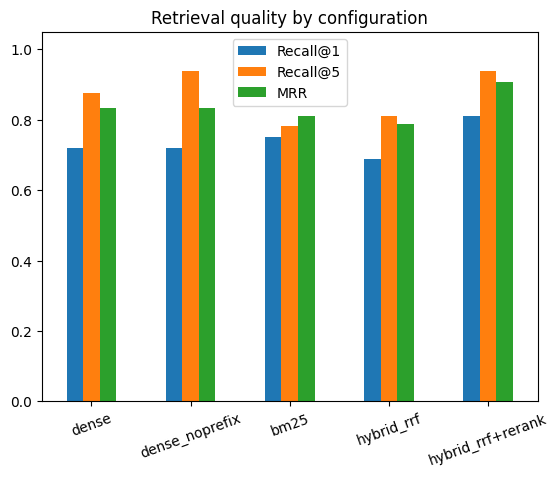

Nota: 'faithful' vem de um juiz que é o mesmo modelo que gera as respostas; ver Q10 para a análise.


In [39]:
summary = pd.DataFrame(RESULTS).T
summary.loc["end-to-end", "answer_acc"] = round(ev.correct.mean(), 3)
summary.loc["end-to-end", "faithful"] = round((ev[ev.faithful.notna()].faithful == True).mean(), 3)
print("Backend:", BACKEND, HF_MODEL if BACKEND == "hf" else ANTHROPIC_MODEL)
display(summary)
summary[["Recall@1", "Recall@5", "MRR"]].dropna().plot.bar(rot=20, title="Retrieval quality by configuration")
plt.ylim(0, 1.05); plt.show()
print("Nota: 'faithful' vem de um juiz que é o mesmo modelo que gera as respostas; ver Q10 para a análise.")

### Report

1. A melhor configuração foi `hybrid_rrf+rerank`, com Recall@1 de 0,812 e MRR de 0,906. Em comparação com a pesquisa densa (0,719 e 0,833), melhorou 0,093 no Recall@1 e 0,073 no MRR. O custo médio também aumentou, de 13,6 para 52,8 ms por pergunta.

2. A pergunta «Quantas vezes posso tentar subir a nota de uma cadeira?» continuou a falhar. A expressão «subir a nota de uma cadeira» não coincide facilmente com «melhoria de classificação» no regulamento, e o reranker não resolve o problema se o documento relevante não aparecer entre os candidatos. Tentaria reescrever a pergunta com o vocabulário dos regulamentos ou enriquecer os artigos com termos equivalentes antes de os indexar.

3. Num chatbot real, começaria por selecionar só as ferramentas e documentos úteis para cada pergunta e resumir o histórico antigo. Na Parte 1, estas alterações reduziram o contexto de 6 832 para 857 tokens, cerca de 87% menos. Isto reduz custos e também a quantidade de informação irrelevante que pode confundir o modelo. Usaria ainda um filtro por data para não misturar versões antigas e atuais dos documentos.

## ★ Bonus (at home or for fast teams)

**B1 · Query rewriting for follow-ups.** `"E posso pagar tudo de uma vez?"` retrieves nothing useful on its own. Rewrite it into a standalone query using the conversation history, then retrieve.

In [41]:
def rewrite_query(history: list, follow_up: str) -> str:
    """Reescreve uma pergunta de seguimento como pergunta autónoma, usando o histórico (sem a responder)."""
    prompt = ("Reescreve a última pergunta do utilizador para que possa ser compreendida sem o histórico. "
              "Mantém exatamente o mesmo sentido, sem acrescentar detalhes que não estejam no histórico, "
              "e não respondas à pergunta. Escreve apenas a nova pergunta, em português europeu.\n\n"
              "Histórico:\n" + "\n".join(history) + "\n\nPergunta de seguimento: " + follow_up)
    return llm(prompt, max_tokens=60).strip()

hist = ["Utilizador: Quanto custa a propina anual em 2026/2027?",
        "Assistente: A propina anual é de 710 euros [propinas-2026]."]
fu = "E posso pagar tudo de uma vez?"
rq = rewrite_query(hist, fu)
print("raw      :", hybrid_rerank(fu, k=3))
print("rewritten:", rq, "->", hybrid_rerank(rq, k=3))
print("\nTraz propinas-2026 no top-3?  sem reescrever:", "propinas-2026" in hybrid_rerank(fu, k=3),
      "| reescrita:", "propinas-2026" in hybrid_rerank(rq, k=3))

raw      : ['regped-art-6', 'reembolso-2023', 'reembolso-2026']
rewritten: Posso fazer um pagamento integral da propina anual em 2026/2027? -> ['propinas-2026', 'propinas-2024', 'reembolso-2026']

Traz propinas-2026 no top-3?  sem reescrever: False | reescrita: True


A pergunta de seguimento sozinha ("E posso pagar tudo de uma vez?") não tem sujeito: a pesquisa devolve excertos que não respondem à pergunta (ver `raw`). Depois de o LLM a reescrever como pergunta autónoma com o histórico, a pesquisa deve passar a trazer `propinas-2026` (ver `rewritten` e a linha final). Cuidados: a reescrita pode deslocar o sentido (por exemplo, trocar "tudo de uma vez" por "em duas parcelas"), por isso o prompt pede para manter o sentido e não acrescentar detalhes, e a pergunta reescrita deve ser usada só para pesquisar, não para substituir a original no prompt final. Mesmo com a reescrita certa, a lista pode trazer versões antigas (`propinas-2024`), que o `latest_only` remove.

**B2 · HyDE.** Generate a hypothetical answer, embed it and search with it. Evaluate as `"hyde"`. Does it help on the paraphrase questions (compare `MISSES["hyde"]` with `MISSES["dense"]`)? What does it cost?

In the original method the hypothetical answer is embedded **as a document**, so with E5 it takes the `passage: ` prefix.

In [ ]:
def hyde_search(query: str, k: int = 10) -> list:
    """HyDE: pesquisa com o vetor de uma resposta hipotética, que "vive" no espaço dos documentos."""
    prompt = ("Escreve um parágrafo curto, no estilo de um regulamento universitário, que responda à pergunta seguinte. "
              "Não cites documentos.\nPergunta: " + query)
    hypo = llm(prompt, max_tokens=80)
    hyp_emb = emb_model.encode("passage: " + hypo, normalize_embeddings=True)   
    best = np.argsort(-(P_EMB @ hyp_emb), kind="stable")[:k]
    return [CHUNKS[i]["id"] for i in best]

if EXECUTAR_BONUS:
    print(evaluate(hyde_search, "hyde"))
    print("dense misses:", MISSES["dense"])
    print("hyde misses :", MISSES["hyde"])
    recovered = [q for q in MISSES["dense"] if q not in MISSES["hyde"]]
    lost = [q for q in MISSES["hyde"] if q not in MISSES["dense"]]
    print("\nHyDE recupera (o denso falhava):", recovered or "nenhuma")
    print("HyDE perde (o denso acertava)  :", lost or "nenhuma")
    display(pd.DataFrame(RESULTS).T.loc[["dense", "hyde"]])
else:
    print("B2 implementado. Põe EXECUTAR_BONUS = True na célula de imports para correr a avaliação HyDE.")

{'Recall@1': 0.531, 'Recall@5': 0.844, 'MRR': 0.734, 'ms/query': 3219.721}
dense misses: ['Quantas vezes posso tentar subir a nota de uma cadeira?', 'Qual é a nota mínima para passar a uma cadeira?']
hyde misses : ['Quantas vezes posso tentar subir a nota de uma cadeira?', 'Qual é a nota mínima para passar a uma cadeira?', 'Quem tem direito a época especial de exames?']

HyDE recupera (o denso falhava): nenhuma
HyDE perde (o denso acertava)  : ['Quem tem direito a época especial de exames?']


,Recall@1,Recall@5,MRR,ms/query
dense,0.719,0.875,0.833,13.627
hyde,0.531,0.844,0.734,3219.721


Nesta experiência o HyDE não melhorou a recuperação. O Recall@1 desceu de 0,719 no denso para 0,531, o Recall@5 de 0,875 para 0,844 e o MRR de 0,833 para 0,734. Não resolveu nenhuma das duas perguntas em que o denso falhava e passou ainda a falhar a pergunta sobre quem tem direito à época especial de exames.

Também foi muito mais lento: 3219,7 ms por pergunta, contra 13,6 ms no denso, porque primeiro precisa de gerar uma resposta hipotética com o LLM. Neste corpus, o custo adicional não compensou.

**B3 · A minimal agentic loop.** If the judge says the answer is unfaithful, or the model abstains, rewrite the query and retrieve again (at most 2 attempts). Log every step. Where could this loop go wrong in production?

In [43]:
def agentic_answer(question: str, max_steps: int = 2) -> dict:
    """Ciclo mínimo: responde, verifica com o juiz e, se falhar ou houver abstenção, reformula e tenta de novo."""
    q, log = question, []
    for step in range(max_steps):
        a = rag_answer(q)
        verdict = judge(a)
        log.append({"step": step, "query": q, "answer": a["answer"], "faithful": verdict.get("faithful")})
        if verdict.get("faithful") and not a["abstained"]:
            break
        if step < max_steps - 1:                      # só reformula se ainda houver uma tentativa a seguir
            prompt = ("Reformula a pergunta para fazer uma nova pesquisa nos documentos da universidade, usando outras palavras "
                      "mas mantendo a intenção original. Responde só com a pergunta, em português europeu.\n"
                      f"Pergunta original: {question}\nPergunta anterior: {q}")
            q = llm(prompt, max_tokens=60).strip().strip("\"' ")
    return {"final": log[-1]["answer"], "log": log}

if EXECUTAR_BONUS:
    res = agentic_answer("Quantas vezes posso tentar subir a nota de uma cadeira?")
    display(pd.DataFrame(res["log"])[["step", "query", "faithful"]])
    for s in res["log"]:
        print(f"\n[step {s['step']}] {s['query']}\n    {s['answer']}")
else:
    print("B3 implementado. Põe EXECUTAR_BONUS = True na célula de imports para correr o ciclo agêntico.")

,step,query,faithful
0,0,Quantas vezes posso tentar subir a nota de uma...,False
1,1,Quantas tentativas de retenção acadêmica é per...,False



[step 0] Quantas vezes posso tentar subir a nota de uma cadeira?
    De acordo com o Regulamento Pedagógico, Artigo 4.º, existe a possibilidade de um aluno recorrer à época de recurso se for reprovado ou se não comparecer à época normal. No entanto, esta opção só está disponível após ter sido solicitada pelo estudante junto ao portal académico. Portanto, dependendo da situação específica do aluno, ele poderá ter várias oportunidades para tentar subir a sua nota.

[step 1] Quantas tentativas de retenção acadêmica é permitido realizar?
    Não sei com base nos documentos disponíveis.


Onde pode falhar em produção: (1) **O ciclo é tão bom como o verificador.** Aqui o juiz é o próprio modelo de 1,5B e marcou como "não fiéis" quase todas as respostas, mesmo as certas (Q10): o ciclo repetiria quase sempre, gastando custo e latência para chegar ao mesmo resultado, e um juiz demasiado brando aceitaria respostas erradas. (2) **Custo e latência multiplicam-se** a cada volta (nova pesquisa, nova geração, novo juízo). (3) **A reformulação pode afastar-se do que o utilizador perguntou** (deriva de sentido), por isso o prompt leva a pergunta original e a anterior. (4) **Abstenções legítimas** (perguntas sem resposta nos documentos) são tratadas como falha e disparam tentativas inúteis, com risco de acabar a inventar. (5) Precisa de um **limite de passos** (aqui 2) e de registo de cada passo para ser auditável; e se a falha vem da recuperação (como a pergunta "da cadeira"), reformular só ajuda se a nova pergunta usar o vocabulário dos documentos.